In [1]:
from IPython.display import HTML, display

display(
    HTML(
        """
<style>
    .jp-Notebook, .jp-Cell, .jp-CodeCell, .jp-MarkdownCell, .jp-OutputArea, .jp-OutputArea-output {
        background-color: #F4F1EA !important;
    }
    .jp-OutputArea-output img {
        display: block;
        margin-left: auto;
        margin-right: auto;
    }
</style>
"""
    )
)

# King County House Sales (May–July 2014)

This project analyzes home sales in King County, Washington (USA), recorded between May 2 and July 10, 2014. For each sale, the dataset includes the price, the size and condition of the home, its view, and the city where it was sold.

## Research question
Which physical and location features are most strongly related to home prices in King County?

### Libraries
- **pandas** – loads the data and handles cleaning, filtering and grouping.
- **matplotlib** – the base library for drawing charts (titles, axes, colors).
- **seaborn** – built on top of matplotlib; creates statistical charts such as the correlation heatmap and the line and scatter plots with less code.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

In [3]:
# Cosmetic only: cream background for all charts
plt.rcParams['figure.facecolor'] = '#efeee8'
plt.rcParams['axes.facecolor'] = '#efeee8'

In [4]:
df=pd.read_csv("house_sales.csv")

In [5]:
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,2014-05-02,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,2014-05-02,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,2014-05-02,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,2014-05-02,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,2014-05-02,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51


### Dataset Features
- **Date** – Date of sale.
- **Price** – Sale price in USD.
- **Bedrooms** – Number of bedrooms.
- **Bathrooms** – Number of bathrooms, counted by fixtures: 1.0 = full bathroom (toilet, sink, shower, bathtub), 0.75 = toilet, sink and shower,
  0.5 = toilet and sink, 0.25 = a single fixture. For example, 2.5 means two full bathrooms plus one half bathroom.
- **Sqft_living** – Interior living area in square feet.
- **Sqft_lot** – Lot (land) area in square feet.
- **Floors** – Number of floors; 1.5 means one full floor plus a partial upper floor, such as an attic.
- **Waterfront** – 1 if the home is on the waterfront, otherwise 0.
- **View** – View quality, rated from 0 (no view) to 4 (excellent view).
- **Condition** – Overall condition, rated from 1 (poor) to 5 (very good). A rating of 3 is average or Standard new build.
- **Sqft_above** – Living area above ground, excluding the basement.
- **Sqft_basement** – Basement area.
- **Yr_built** – Year the home was built.
- **Yr_renovated** – Year of the last renovation (0 = never renovated).
- **Street, City, Statezip** – Street address, city and ZIP code.
- **Price_per_sqft** – Price per square foot of living area.

##  Data Overview
The dataset contains 4,600 sales and 18 columns. Below I check the data types, missing values and duplicate rows.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            4600 non-null   str    
 1   price           4600 non-null   float64
 2   bedrooms        4600 non-null   float64
 3   bathrooms       4600 non-null   float64
 4   sqft_living     4600 non-null   int64  
 5   sqft_lot        4600 non-null   int64  
 6   floors          4600 non-null   float64
 7   waterfront      4600 non-null   int64  
 8   view            4600 non-null   int64  
 9   condition       4600 non-null   int64  
 10  sqft_above      4600 non-null   int64  
 11  sqft_basement   4600 non-null   int64  
 12  yr_built        4600 non-null   int64  
 13  yr_renovated    4600 non-null   int64  
 14  street          4600 non-null   str    
 15  city            4600 non-null   str    
 16  statezip        4600 non-null   str    
 17  price_per_sqft  4600 non-null   float64
dtyp

In [7]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,price_per_sqft
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261,265.876209
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536,357.503362
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000,180.817500
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000,243.855000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000,314.840000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000,22533.900000


In [8]:
df.describe(include=['str'])

,date,street,city,statezip
count,4600,4600,4600,4600
unique,70,4525,44,77
top,2014-06-23,2520 Mulberry Walk NE,Seattle,WA 98103
freq,142,4,1573,148


In [9]:
#Checking for missing values.
df.isnull().sum()

date              0
price             0
bedrooms          0
bathrooms         0
sqft_living       0
sqft_lot          0
floors            0
waterfront        0
view              0
condition         0
sqft_above        0
sqft_basement     0
yr_built          0
yr_renovated      0
street            0
city              0
statezip          0
price_per_sqft    0
dtype: int64

In [10]:
#Checking for duplicate rows.
df.duplicated().sum()

np.int64(0)

In [11]:
# Convert the sale date to a date type
df["date"]=pd.to_datetime(df["date"])

# Readable labels for tables and charts (the numeric columns stay for the correlation analysis)
df["waterfront_label"]=df["waterfront"].astype(str).replace({"0": "No", "1": "Yes"})
df["condition_label"]=df["condition"].astype(str).replace({"1": "Poor", "2": "Fair","3": "Average", "4": "Good","5": "Very Good"})
df["view_label"]=df["view"].astype(str).replace({"0": "No view", "1": "Fair","2": "Average", "3": "Good","4": "Excellent"})

##  Data Cleaning

### Invalid prices
49 sales (about 1% of the data) have a price of $0, which is not a real sale price. Price is the variable I want to explain, so filling it with an average would add guesses instead of facts. I remove these rows.

In [12]:
zero_price=df.query("price==0")
zero_price.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft,waterfront_label,condition_label,view_label
4354,2014-05-05,0.0,3.0,1.75,1490,10125,1.0,0,0,4,...,0,1962,0,3911 S 328th St,Federal Way,WA 98001,0.0,No,Good,No view
4356,2014-05-05,0.0,4.0,2.75,2600,5390,1.0,0,0,4,...,1300,1960,2001,2120 31st Ave W,Seattle,WA 98199,0.0,No,Good,No view
4357,2014-05-05,0.0,6.0,2.75,3200,9200,1.0,0,2,4,...,1600,1953,1983,12271 Marine View Dr SW,Burien,WA 98146,0.0,No,Good,Average
4358,2014-05-06,0.0,5.0,3.50,3480,36615,2.0,0,0,4,...,990,1983,0,21809 SE 38th Pl,Issaquah,WA 98075,0.0,No,Good,No view
4361,2014-05-07,0.0,5.0,1.50,1500,7112,1.0,0,0,5,...,740,1920,0,14901-14999 12th Ave SW,Burien,WA 98166,0.0,No,Very Good,No view


In [13]:
len(zero_price)

49

In [14]:
df=df.drop(zero_price.index)

### Homes with no bedrooms and no bathrooms
Two homes are listed with 0 bedrooms and 0 bathrooms, even though they are large (3,064 and 4,810 sq ft) and sold for over $1 million. This is most likely missing data, not real studios. I looked for similar homes to estimate the missing values, but found none (see below), so I removed both rows.

In [15]:
no_baths=df.query("bathrooms==0")
no_baths

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft,waterfront_label,condition_label,view_label
2365,2014-06-12,1095000.0,0.0,0.0,3064,4764,3.5,0,2,3,...,0,1990,2009,814 E Howe St,Seattle,WA 98102,357.38,No,Average,Average
3209,2014-06-24,1295648.0,0.0,0.0,4810,28008,2.0,0,0,3,...,0,1990,2009,20418 NE 64th Pl,Redmond,WA 98053,269.37,No,Average,No view


In [16]:
# Looking for similar homes (same size, floors and no waterfront)
df.query("2900<sqft_living<3200 and floors==3.5 and waterfront_label=='No'")

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft,waterfront_label,condition_label,view_label
2365,2014-06-12,1095000.0,0.0,0.0,3064,4764,3.5,0,2,3,...,0,1990,2009,814 E Howe St,Seattle,WA 98102,357.38,No,Average,Average


In [17]:
#It can be observed that there are no comparable properties
df.query("4500<sqft_living<5000 and floors==2 and waterfront_label=='No' and view_label=='No view' and 26000<sqft_lot<30000 ")

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft,waterfront_label,condition_label,view_label
3209,2014-06-24,1295648.0,0.0,0.0,4810,28008,2.0,0,0,3,...,0,1990,2009,20418 NE 64th Pl,Redmond,WA 98053,269.37,No,Average,No view


In [18]:
#Consequently, these two anomalous rows with invalid physical attributes are removed from the dataset to maintain data integrity.
df=df.drop(no_baths.index)

### Build year and renovation year
In some homes the renovation year is earlier than the year the home was built, which is impossible. All the values are valid years, so it looks like the two columns were swapped in these rows. I swapped them back instead of deleting the homes. This is an assumption, but it keeps the data and the prices of these homes.

In [19]:
# Rows where the renovation year is earlier than the build year
df.query("yr_renovated > 0 and yr_renovated < yr_built")

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft,waterfront_label,condition_label,view_label
31,2014-05-02,499950.00,4.0,2.50,2860,3345,2.0,0,0,3,...,670,2004,2003,20120 137th Ave NE,Woodinville,WA 98072,174.81,No,Average,No view
60,2014-05-02,555000.00,4.0,2.50,3310,6500,2.0,0,0,3,...,0,2012,1912,35229 SE Terrace St,Snoqualmie,WA 98065,167.67,No,Average,No view
61,2014-05-02,459990.00,3.0,2.50,2680,5539,2.0,0,0,3,...,0,2013,1923,13800 453rd Ave SE,North Bend,WA 98045,171.64,No,Average,No view
64,2014-05-03,625000.00,4.0,2.75,2920,6605,2.0,0,0,3,...,0,2012,1912,5608 NE 5th Cir,Renton,WA 98059,214.04,No,Average,No view
68,2014-05-04,775000.00,2.0,2.50,2680,7392,1.0,0,0,3,...,0,2004,2003,13134 234th Ct NE,Redmond,WA 98053,289.18,No,Average,No view
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4403,2014-05-19,646212.50,4.0,2.50,3430,64441,2.0,0,0,3,...,0,2013,1923,19585-19799 204th Ave NE,Woodinville,WA 98077,188.40,No,Average,No view
4434,2014-05-29,484991.67,4.0,2.75,2320,4344,2.0,0,0,3,...,0,2012,1912,4242 NE 2nd Ct,Renton,WA 98059,209.05,No,Average,No view
4441,2014-05-30,790000.00,4.0,2.50,2310,5100,2.0,0,0,3,...,0,2013,1923,144 NW 103rd St,Seattle,WA 98177,341.99,No,Average,No view
4504,2014-06-17,331366.67,3.0,2.50,1270,2509,2.0,0,0,3,...,0,2004,2003,2492 SW Webster St,Seattle,WA 98106,260.92,No,Average,No view


In [20]:
#Swap the two columns in these rows.
mask=(df['yr_renovated']>0)&(df['yr_built']>df['yr_renovated'])
df.loc[mask,['yr_built','yr_renovated']]=df.loc[mask,['yr_renovated','yr_built']].values

In [21]:
# Check: no impossible rows remain.
df.query("yr_renovated > 0 and yr_renovated < yr_built")

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft,waterfront_label,condition_label,view_label


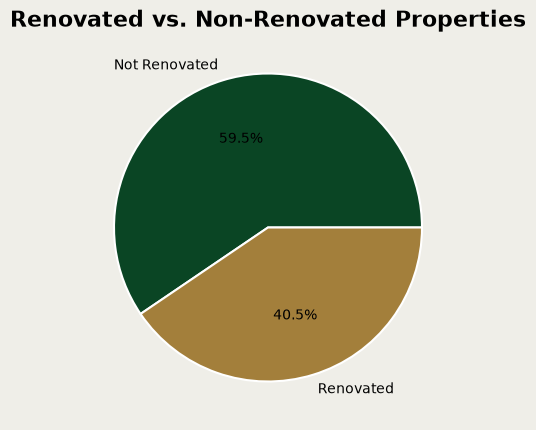

In [22]:
#I want to check how many properties were renovated compared to properties that were not renovated.
renovated_count=((df['yr_renovated'] > 0).replace({True: 'Renovated', False: 'Not Renovated'}).value_counts())


plt.figure(figsize=(6, 5))
plt.pie(renovated_count,labels=renovated_count.index,autopct='%1.1f%%',colors=['#0a4524','#a37f3b'],wedgeprops={'edgecolor':'white','linewidth': 1.5})
plt.title('Renovated vs. Non-Renovated Properties',fontsize=16,weight='bold')
plt.show()

In [23]:
#Checking for physical inconsistencies between the lot size and the living area.
df.query("sqft_living > sqft_lot")

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft,waterfront_label,condition_label,view_label
22,2014-05-02,626000.00,3.0,2.25,1750,1572,2.5,0,0,3,...,280,2005,0,3140 Franklin Ave E,Seattle,WA 98102,357.71,No,Average,No view
48,2014-05-02,445700.00,3.0,2.50,1270,1180,3.0,0,0,3,...,0,2001,0,2640 NW 56th St,Seattle,WA 98107,350.94,No,Average,No view
59,2014-05-02,295000.00,2.0,2.50,1630,1368,2.0,0,0,3,...,350,2009,0,5944-6082 Delridge Way SW,Seattle,WA 98106,180.98,No,Average,No view
75,2014-05-05,531000.00,2.0,3.00,1270,1175,2.0,0,0,3,...,160,2000,0,1411 N 48th St,Seattle,WA 98103,418.11,No,Average,No view
88,2014-05-05,405000.00,2.0,3.00,1410,1240,2.0,0,0,3,...,270,2006,0,9126 45th Ave SW,Seattle,WA 98136,287.23,No,Average,No view
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4391,2014-05-15,274750.00,4.0,2.50,1840,1562,2.0,0,0,3,...,440,2003,2004,2414 SW Holden St,Seattle,WA 98106,149.32,No,Average,No view
4465,2014-06-05,2560498.33,3.0,2.50,1710,1664,2.0,0,0,5,...,410,2003,0,2826 21st Ave W,Seattle,WA 98199,1497.37,No,Very Good,No view
4543,2014-06-25,360500.00,3.0,2.50,1150,887,3.0,0,0,3,...,0,2007,0,10703 Greenwood Ave N,Seattle,WA 98133,313.48,No,Average,No view
4573,2014-07-02,584000.00,3.0,1.75,1490,1036,2.0,0,0,3,...,400,2008,0,4304B 36th Ave W,Seattle,WA 98199,391.95,No,Average,No view


### Living area larger than the lot
171 homes have a living area that is larger than the lot. This is possible when a building has several floors on a small lot, as in townhouses and compact urban homes. To check this properly, I compared the lot size with the building footprint (above ground area divided by the number of floors). In all but one of these homes the footprint fits inside the lot. In the remaining home it exceeds the lot by only 18 sq ft (about 2%), which is within measurement error, so I kept all of them.

In [24]:
# Building footprint=above ground area divided by the number of floors
df["footprint"]=df["sqft_above"]/df["floors"]
df.query("footprint > sqft_lot")

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,yr_built,yr_renovated,street,city,statezip,price_per_sqft,waterfront_label,condition_label,view_label,footprint
4130,2014-07-08,530000.0,2.0,2.5,1785,779,2.0,0,0,3,...,1975,0,1600-1718 107th Ave SE,Bellevue,WA 98004,296.92,No,Average,No view,797.5


In [25]:
#Checking for out-of-range transaction dates to ensure temporal consistency.
df.query("date < '2014-05-02' or date > '2014-07-10'")

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,yr_built,yr_renovated,street,city,statezip,price_per_sqft,waterfront_label,condition_label,view_label,footprint


In [26]:
#Inspected the smallest living area values to verify that extreme low-end figures represent valid small dwellings rather than data entry errors.
df.sqft_living.nsmallest(20)

3778    370
2919    380
2416    420
1219    430
4184    490
4368    520
1216    550
1833    560
1283    580
1191    590
4338    590
2318    620
3444    620
4147    630
586     650
1906    650
3266    650
2770    660
3945    660
1861    670
Name: sqft_living, dtype: int64

In [27]:
df.sqft_living.nlargest(20)

122     13540
2286    10040
2654     9640
2328     8670
4138     7320
462      7270
3729     7050
1567     6980
2967     6900
3559     6640
3004     6630
4135     6500
839      6490
2761     6430
3202     6390
252      6210
4283     6070
2731     6050
1182     6040
2846     5990
Name: sqft_living, dtype: int64

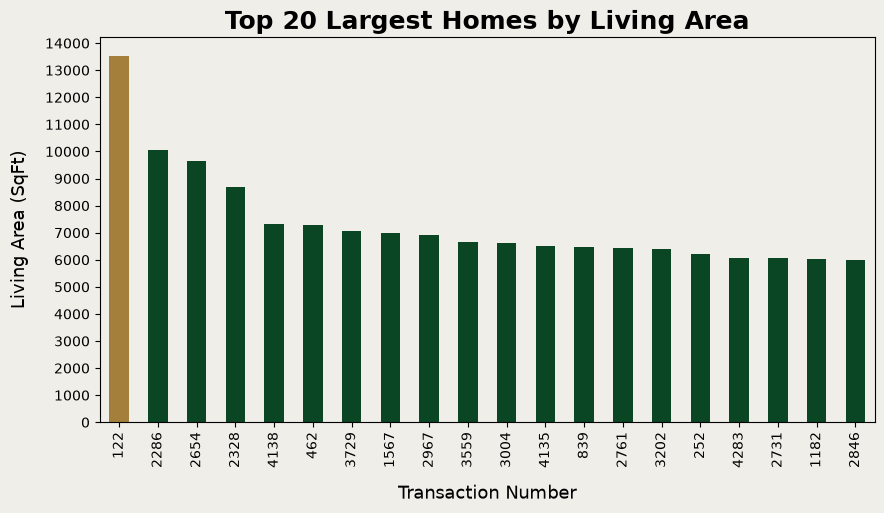

In [28]:
l=df.sqft_living.nlargest(20)
l.plot(kind="bar", color=["#a37f3b"]+["#0a4524"]*19,figsize=(10, 5))
plt.title("Top 20 Largest Homes by Living Area", fontsize=18, weight="bold")
plt.xlabel("Transaction Number", fontsize=13,labelpad=12)
plt.ylabel("Living Area (SqFt)", fontsize=13,labelpad=12)
plt.yticks(range(0,15000, 1000))
plt.show()
#It is evident that an extreme outlier exists in terms of living area, requiring removal to ensure an accurate representation of the dataset.

In [29]:
df = df.drop(index=122)

In [30]:
df.price.nlargest(20)

4350    26590000.00
4346    12899000.00
2286     7062500.00
2654     4668000.00
2761     4489000.00
3729     3800000.00
1637     3710000.00
252      3200000.00
1567     3100000.00
2772     3000000.00
2328     2888000.00
1571     2750000.00
1132     2700000.00
2083     2700000.00
4261     2680000.00
4465     2560498.33
581      2555000.00
2712     2475000.00
3202     2466350.00
4135     2458000.00
Name: price, dtype: float64

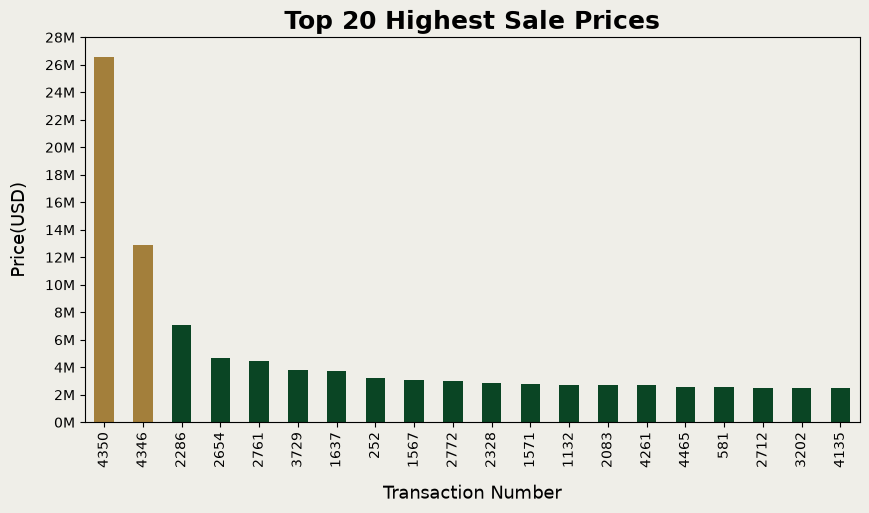

In [31]:
lp=df.price.nlargest(20)/1000000
lp.plot(kind='bar',figsize=(10, 5),color=["#a37f3b"]+["#a37f3b"]+["#0a4524"]*18)
plt.title("Top 20 Highest Sale Prices",fontsize=18,weight="bold")
plt.xlabel("Transaction Number",fontsize=13,labelpad=12)
plt.ylabel("Price(USD)", fontsize=13,labelpad=12)
plt.yticks(range(0,29,2),[f"{i}M" for i in range(0,29,2)])
plt.show()

In [32]:
df=df.drop(index=[4350, 4346])
#It can be seen that there are two extreme outlier transactions, so I am removing them in order to prevent them from skewing the statistical analysis.

In [33]:
df.price.nsmallest(20)

4351      7800.00
1219     80000.00
1587     83000.00
4407     83300.00
4415     83300.00
4345     84350.00
4425     87500.00
588      90000.00
1283     90000.00
290     100000.00
2203    100000.00
3643    100000.00
3945    100000.00
3769    102500.00
4387    107500.00
4447    108333.33
529     110000.00
2329    110000.00
908     110700.00
4113    115000.00
Name: price, dtype: float64

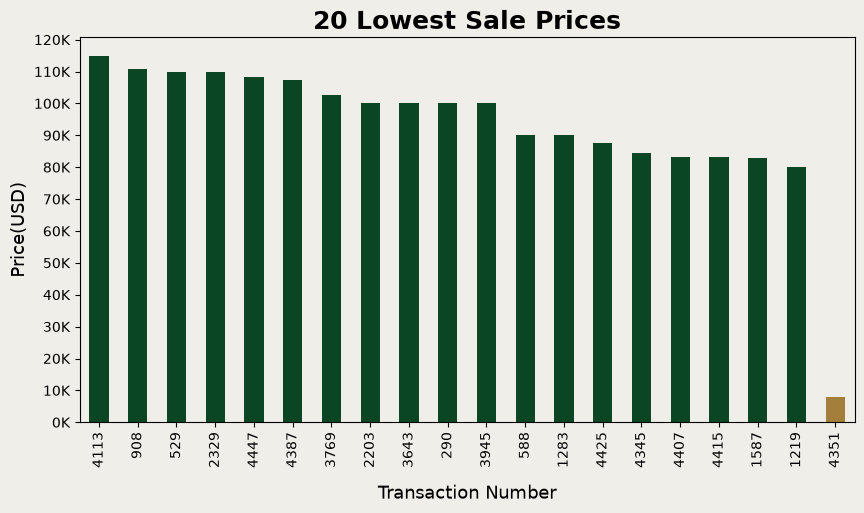

In [34]:
sp=df.price.nsmallest(20).sort_values(ascending=False)/1000
sp.plot(kind='bar',figsize=(10,5),color=["#0a4524"]*19+["#a37f3b"])
plt.title("20 Lowest Sale Prices", fontsize=18, weight="bold")
plt.xlabel("Transaction Number", fontsize=13, labelpad=12)
plt.ylabel("Price(USD)", fontsize=13)
plt.yticks(range(0,130,10),[f"{i}K" for i in range(0,130,10)])
plt.show()

In [35]:
df=df.drop(index=4351)
#It can be seen that there is an extremely low transaction, so I am removing it to prevent it from skewing the data analysis.

### Extreme values
- **Largest home:** One home has 13,540 sq ft, about 35% more than the next largest (10,040 sq ft). The second one sold for 7.1 million USD, which fits a luxury home, so I kept it. I removed only the 13,540 sq ft home, because it would distort averages and scatter plots.
- **Highest prices:** Two sales (26.6 million USD and 12.9 million USD) are far above the next highest (7.1 million USD), and they may be genuine sales of extremely luxurious homes. They are so rare that they would distort the averages and charts, and this analysis focuses on typical homes, so I excluded them as outliers. This is an analytical choice, not a correction of errors.
- **Lowest price:** One sale at 7,800 USD is far below the next lowest (80,000 USD). It may not be a regular market sale (for example, a transfer between relatives), so I excluded it as an outlier.

In total, I removed 55 of 4,600 rows (1.2%).

After cleaning, 4,545 sales remain. Next, I look at the distribution of the main features.

In [36]:
# 4,470 different streets for 4,545 sales
df["street"].nunique()

4470

In [37]:
# Street is too detailed to group by, and the city already gives the geographic level I need
df=df.drop(columns=["street", "statezip"])

In [38]:
#Distribution of Bedrooms.
df.groupby('bedrooms').bedrooms.count()

bedrooms
1.0      37
2.0     560
3.0    2023
4.0    1512
5.0     338
6.0      59
7.0      13
8.0       2
9.0       1
Name: bedrooms, dtype: int64

In [39]:
#Distribution of Bathrooms.
df.groupby('bathrooms').bathrooms.count()

bathrooms
0.75      17
1.00     735
1.25       3
1.50     287
1.75     628
2.00     424
2.25     413
2.50    1183
2.75     270
3.00     164
3.25     135
3.50     159
3.75      34
4.00      21
4.25      22
4.50      26
4.75       7
5.00       5
5.25       4
5.50       4
5.75       1
6.25       1
6.50       1
6.75       1
Name: bathrooms, dtype: int64

In [40]:
#Distribution by floors.
df.groupby('floors').floors.count()

floors
1.0    2148
1.5     439
2.0    1790
2.5      41
3.0     126
3.5       1
Name: floors, dtype: int64

In [41]:
#Distribution by waterfront access.
df.groupby('waterfront_label').waterfront.count()

waterfront_label
No     4515
Yes      30
Name: waterfront, dtype: int64

In [42]:
#View rating distribution.
df.groupby('view_label').view.count().sort_values(ascending=False)

view_label
No view      4099
Average       200
Good          115
Fair           69
Excellent      62
Name: view, dtype: int64

In [43]:
#Distribution by condition rating
df.groupby('condition_label').condition.count().sort_values(ascending=False)

condition_label
Average      2847
Good         1237
Very Good     425
Fair           31
Poor            5
Name: condition, dtype: int64

In [44]:
df.groupby('city')['price'].agg(['count','median']).sort_values('median',ascending=False)

,count,median
city,,
Medina,11,2100000.000
Yarrow Point,4,1397000.000
Clyde Hill,9,1325000.000
Mercer Island,82,950466.665
Beaux Arts Village,1,745000.000
Bellevue,281,725000.000
Sammamish,171,668500.000
Redmond,233,635000.000
Newcastle,33,602500.000


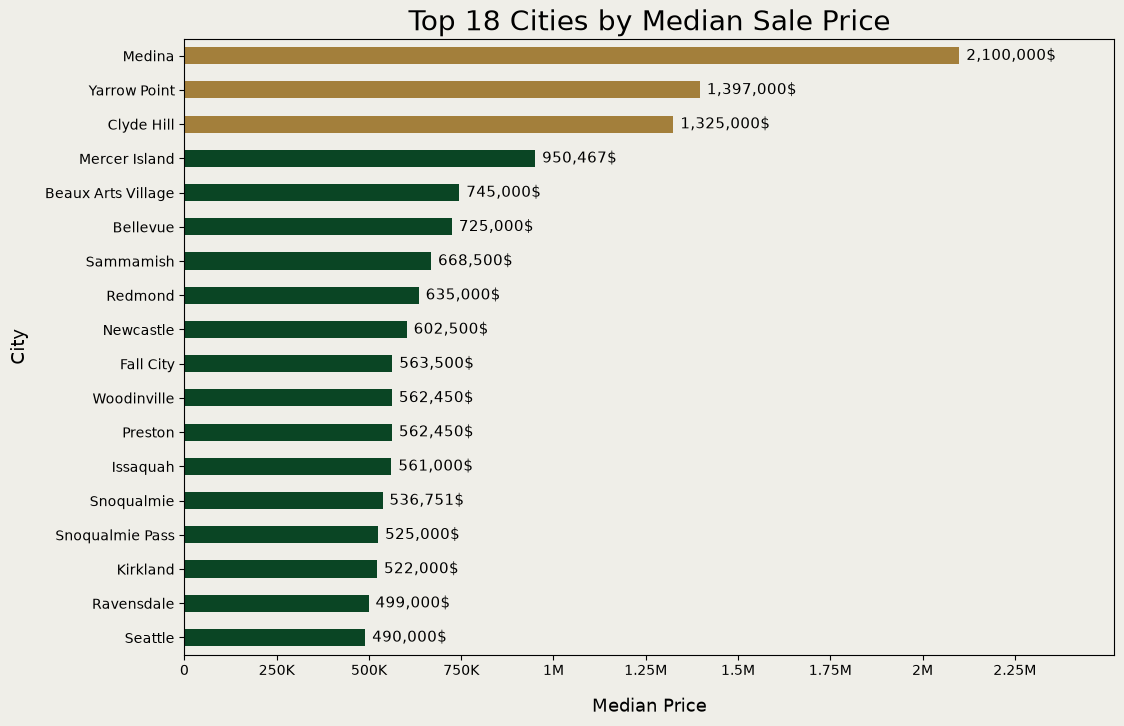

In [45]:
avg_p=df.groupby('city')['price'].median().sort_values(ascending=True).tail(18)


z=avg_p.plot(kind="barh",figsize=(12,8),color=["#0a4524"]*15+["#a37f3b"]+["#a37f3b"]+["#a37f3b"])
plt.title('Top 18 Cities by Median Sale Price', fontsize=20)
plt.xlabel('Median Price',  fontsize=13, labelpad=14)
plt.ylabel('City', fontsize=13, labelpad=12)
plt.xticks([0,250000,500000,750000,1000000,1250000,1500000,1750000,2000000,2250000],
           ['0','250K','500K','750K','1M','1.25M','1.5M','1.75M','2M','2.25M'])
plt.xlim(0, avg_p.max() * 1.2)
for c in z.containers:
  z.bar_label(c, fmt="{:,.0f}$", padding=5, fontsize=11)
plt.show()

**Seattle is the largest market, but not the most expensive.** It accounts for 34% of all sales (1,559 of 4,545 homes), yet its median price (490,000 USD) ranks only 18th among the 44 cities.

The chart shows the 18 cities with the highest median sale price. The four most expensive are small, wealthy communities around Lake Washington: Medina, Yarrow Point, Clyde Hill and Mercer Island. Medina, for example, has only 11 sales, but its median price is 2,100,000 USD, about 4.3 times higher than Seattle's. The larger Eastside cities follow: Bellevue (725,000 USD, 281 sales), Sammamish (668,500 USD) and Redmond (635,000 USD).

Some cities in the chart have very few sales: Beaux Arts Village (1 sale), Preston (2 sales) and Yarrow Point (4 sales). Their medians are based on a handful of homes and are less reliable.

--------------------------------------------------------------------------------------------------------------------------------------------

### Size matters, and location adds to it
**Goal of the chart:** the earlier charts showed that the most expensive cities are small and wealthy. The question now is whether these cities are expensive simply because their homes are bigger, or because of the location itself. To check this, I place each of the 10 most expensive cities on one chart: home size on the horizontal axis and price on the vertical axis.

**The median and not the average:** each city has a few very expensive homes, and in small cities one luxury sale can pull the average up a lot. The median (the middle value) is not affected by these extremes, so it describes the typical home in the city. I use the median for both price and size, so that both axes describe the typical home.

**At least 20 sales:** a median based on only a few homes is not reliable, so I include only cities with 20 or more sales. The bubble size shows the number of sales in each city.

In [46]:
expensive_cities=df.groupby("city").agg(sales_count=("price","count"),
                                        median_price=("price","median"),
                                        median_sqft=("sqft_living","median"))
expensive_cities=expensive_cities.query("sales_count >= 20")
expensive_cities=expensive_cities.sort_values("median_price",ascending=False).head(10)
expensive_cities

,sales_count,median_price,median_sqft
city,,,
Mercer Island,82,950466.665,3055.0
Bellevue,281,725000.000,2450.0
Sammamish,171,668500.000,2790.0
Redmond,233,635000.000,2375.0
Newcastle,33,602500.000,2550.0
Woodinville,114,562450.000,2615.0
Issaquah,186,561000.000,2270.0
Snoqualmie,69,536751.000,2500.0
Kirkland,187,522000.000,2020.0


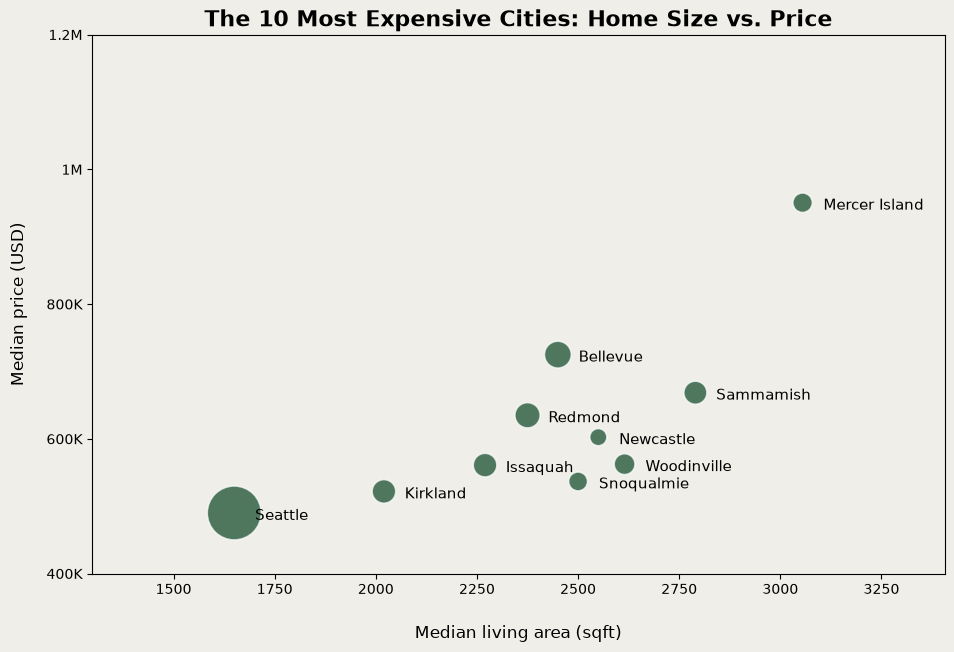

In [47]:
# Each bubble is a city, bigger bubble=more sales
plt.figure(figsize=(11,7))
sb.scatterplot(data=expensive_cities, x="median_sqft", y="median_price", size="sales_count",
                sizes=(150,1500),color="#0a4524",alpha=0.7,legend=False)
plt.title("The 10 Most Expensive Cities: Home Size vs. Price",fontsize=16,weight="bold")
plt.xlabel("Median living area (sqft)",fontsize=12,labelpad=20)
plt.ylabel("Median price (USD)",fontsize=12,labelpad=14)
plt.yticks([400000, 600000, 800000, 1000000, 1200000],
           ["400K", "600K", "800K", "1M", "1.2M"])
for city, row in expensive_cities.iterrows():
    plt.annotate(city,(row["median_sqft"],row["median_price"]),
                 textcoords="offset points", xytext=(15,-5), fontsize=11)
plt.margins(x=0.25)    
plt.show()



**Conclusion: size matters, and location adds to it.**
Among the 10 most expensive cities, price does not simply follow home size. Cities with similar median living areas can have very different median prices, so part of the premium comes from the location and not only from the square footage. The bubble size also shows that these expensive cities are small markets: most of them have far fewer sales than Seattle, so a few luxury sales can strongly affect their numbers. This is why I use the median and only include cities with at least 20 sales. It supports the main finding of the project: living area is the strongest single factor related to price, and location adds to it.

### Age of the homes

In [48]:
#Number of homes per year from 1900 to 1910, is 1900 far above the nearby years?
df["yr_built"].value_counts().sort_index().head(11)

yr_built
1900    22
1901     9
1902    10
1903    10
1904     9
1905    19
1906    27
1907    12
1908    19
1909    22
1910    32
Name: count, dtype: int64

In [49]:
# Compare the age of homes in Seattle with all other cities
df["city_group"]=df["city"].apply(lambda x: "Seattle" if x == "Seattle" else "Other Cities")
df["is_old"]=df["yr_built"] < 1950
df["is_new"]= df["yr_built"] == 2014
age=df.groupby("city_group")[["is_old", "is_new"]].mean()*100
age.columns=["Old homes(built before 1950)-PCT","New homes(built in 2014)-PCT"]
age.round(1)

,Old homes(built before 1950)-PCT,New homes(built in 2014)-PCT
city_group,,
Other Cities,8.8,1.7
Seattle,58.1,1.7


In [50]:
#How many of the homes are new, and what is their condition?
new_homes=df.query("yr_built==2014")
new_homes["condition"].value_counts()

condition
3    78
Name: count, dtype: int64

In [51]:
#How many percent of new homes are built without a basement floor?
(new_homes["sqft_basement"] == 0).mean()*100

np.float64(80.76923076923077)

In [52]:
#Which cities have new construction?
new_homes["city"].value_counts()

city
Seattle          27
Issaquah         10
Auburn            8
Kirkland          5
Renton            5
Redmond           4
Sammamish         4
Maple Valley      3
Snoqualmie        2
Shoreline         1
Federal Way       1
Des Moines        1
Bothell           1
Bellevue          1
Burien            1
Black Diamond     1
North Bend        1
Enumclaw          1
Mercer Island     1
Name: count, dtype: int64

In [53]:
#Summary statistics of the 78 homes built in 2014 (all sold between May and July 2014)
new_homes.describe(percentiles=[0.1, 0.2, 0.5, 0.8, 0.9])[["price","sqft_lot","floors","bathrooms","sqft_basement"]]

,price,sqft_lot,floors,bathrooms,sqft_basement
count,7.800000e+01,78.000000,78.000000,78.000000,78.000000
mean,6.076452e+05,4798.205128,2.115385,2.621795,115.512821
min,2.240000e+05,638.000000,1.000000,1.250000,0.000000
10%,3.228301e+05,1247.800000,2.000000,1.750000,0.000000
20%,3.540738e+05,1615.000000,2.000000,2.500000,0.000000
50%,5.415125e+05,4294.000000,2.000000,2.500000,0.000000
80%,8.243294e+05,6464.200000,2.000000,3.000000,0.000000
90%,9.726930e+05,8416.400000,3.000000,3.500000,546.000000
max,2.351956e+06,21195.000000,3.000000,4.250000,1010.000000
std,3.131275e+05,3664.765793,0.394138,0.555000,264.362244


Homes were built between 1900 and 2014. A quarter were built before 1951, and a quarter after 1997. A few notes:
- **New construction:** 78 homes were built in 2014. Compared with all homes, they sit on much smaller lots (about 4,800 vs. 14,800 sqft on average), have more floors (2.1 vs. 1.5) and more bathrooms (2.6 vs. 2.2). About 90% of them sold for less than 1 million USD (median: about 540,000 USD).
- **Basement and location:** About 81% of the new homes have no basement. They were sold in 19 cities, mostly in Seattle (27 of the 78 homes), Issaquah (10) and Auburn (8).
- **Condition ratings:** All 78 new homes are rated 3-average. The rating describes the condition relative to the home's age, so a 3 for a new home is not the same as a 3 for a 100-year-old home. This may explain why condition shows almost no correlation with price later in the analysis.
- **Seattle:** 58.1% of the homes in Seattle were built before 1950, compared with only 8.8% in the other cities. The share of new homes (built in 2014) is the same in both groups, 1.7%. Seattle is much older, which fits a city that grew early. I define an old home as one built before 1950, which is close to the oldest quarter of all homes in the data.
- **Year 1900:** 22 homes were built in 1900. This is similar to the nearby years (between 9 and 32 homes per year from 1901 to 1910), so 1900 does not look like a default value for an unknown year, and I keep these homes in the analysis.

---------------------------------------------------------------------------------------------------------------------------------------------

## Key Findings from the Exploration

### Home characteristics
- **Bedrooms:** Most homes have 3 bedrooms (45%) or 4 bedrooms (33%).
- **Bathrooms:** The most common value is 2.5 bathrooms (26% of homes): two full bathrooms plus a half bathroom.
- **Floors:** Single-story homes are the most common (47%), followed by two-story homes (39%).

### Views and condition
- **Waterfront:** Only 30 homes (0.7%) are on the waterfront.
- **View:** 90% of the homes have no view, and only 62 homes (1.4%) have an excellent view.
- **Condition:** Most homes are in average condition (63%), 27% are in good condition, and only 5 homes are in poor condition.

### Location
- **Seattle** is the largest market with 1,559 sales (34%), more than five times the second city, Renton (291 sales). Bellevue is third (281 sales).
- **Prices differ strongly between cities.** The most expensive cities are small and wealthy, not the biggest ones.

### Age of the homes
- A quarter of the homes were built before 1951 and a quarter after 1997.
- 78 homes are new construction (built in 2014). They tend to have small lots and more floors, and about 81% have no basement.

##  Weekly Trends
To see how the market changed over time, I grouped the sales by week and calculated, for each week, the number of sales and the average price. The first week (starting Friday, May 2) and the last week (ending Thursday, July 10) are incomplete, so I excluded them. This leaves 9 full weeks.

In [54]:
# Create a column with the week number
df["week"]=df["date"].dt.isocalendar().week

# Group the sales by week
week_table=(df.groupby("week").agg(sales=("price","count"),
                               avg_price=("price", "mean"),
                               median_price=("price", "median")).reset_index())

# Drop the first and last weeks, which are incomplete
week_table=week_table.iloc[1:-1].copy()

# Label each week with the date of its Monday
week_mapping = {19:"May 5",20:"May 12",21:"May 19",22:"May 26",23:"Jun 2",24:"Jun 9",25:"Jun 16",26:"Jun 23",27:"Jun 30"}
week_table["week_label"]=week_table["week"].map(week_mapping)
week_table

,week,sales,avg_price,median_price,week_label
1,19,419,544214.348115,483500.0,May 5
2,20,404,539053.243119,475000.0,May 12
3,21,479,517484.534990,440000.0,May 19
4,22,375,567110.679893,465000.0,May 26
5,23,452,540897.455752,470500.0,Jun 2
6,24,460,556247.728826,475000.0,Jun 9
7,25,531,582193.979228,473000.0,Jun 16
8,26,626,509783.719904,428450.0,Jun 23
9,27,362,611354.195414,499495.0,Jun 30


In [55]:
# Correlation between the number of sales, the average price and the median price.
week_table[["sales","avg_price","median_price"]].corr()

,sales,avg_price,median_price
sales,1.000000,-0.549638,-0.746274
avg_price,-0.549638,1.000000,0.806792
median_price,-0.746274,0.806792,1.000000


The correlation shows that weeks with more sales tended to have lower prices. To see which weeks drive this pattern, I plotted both measures over time: the first chart shows the number of sales per week, and the second shows the average sale price per week.

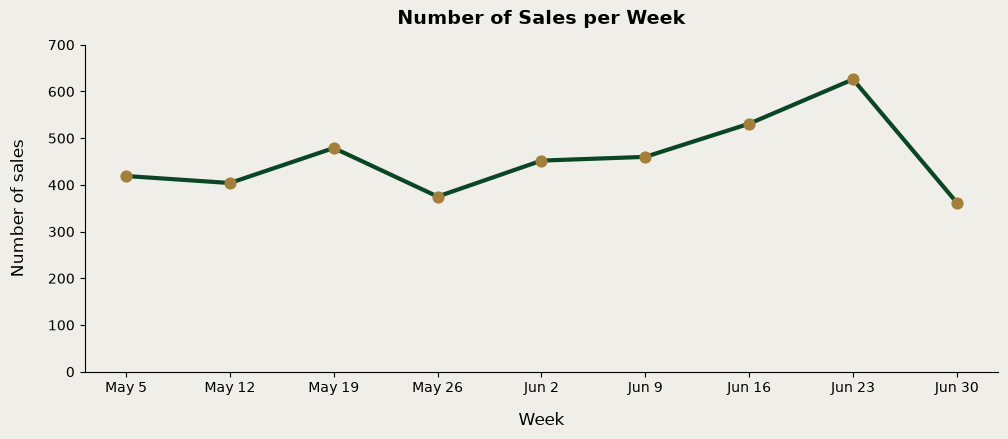

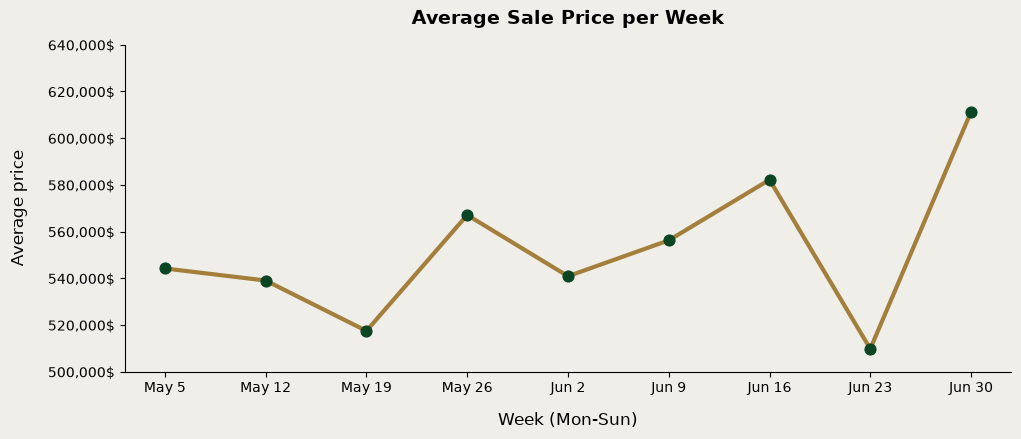

In [56]:
g1=sb.relplot(data=week_table,x="week_label",y="sales",kind="line",height=4,aspect=2.5
           ,linewidth=3,marker='o',markersize=8,mfc="#a37f3b",mec="#a37f3b",color="#0a4524")
plt.title("Number of Sales per Week", fontsize=14, pad=15, weight='bold')
plt.xlabel("Week", labelpad=12, fontsize=12)
plt.ylabel("Number of sales", labelpad=15, fontsize=12)
plt.yticks(range(0,800,100))
plt.show()


g2=sb.relplot(data=week_table,x="week_label",y="avg_price",kind="line",height=4,aspect=2.5
           ,linewidth=3,marker='o',markersize=8,mfc="#0a4524",mec="#0a4524",color="#a37f3b")
plt.title('Average Sale Price per Week', fontsize=14, pad=15, weight='bold')
plt.xlabel("Week (Mon-Sun)", labelpad=12, fontsize=12)
plt.ylabel("Average price", labelpad=15, fontsize=12)
plt.yticks([500000,520000,540000,560000,580000,600000,620000,640000],
          ['500,000$','520,000$','540,000$','560,000$','580,000$','600,000$','620,000$','640,000$'])
plt.show()


The correlation between the weekly number of sales and the weekly average price is -0.55, and the correlation with the weekly median price is -0.75. Both are negative: in weeks with more sales, prices tended to be lower. The relationship with the median is even stronger, so this is not just a few luxury sales distorting the average: the typical home sold in a busy week was cheaper. With only 9 full weeks, this is a rough indication, not proof.

**What the charts show**
- The busiest week was June 23–29 (the point labelled "Jun 23" on the charts), with 626 sales. In that week the average price was the lowest of the period (about 510,000 USD).
- The following week (June 30–July 6, the last point on the charts, labelled "Jun 30") had the fewest sales of all full weeks (362) and the highest average price (about 611,000 USD).
- A possible explanation is the mix of homes. In busy weeks more lower-priced homes are sold, which lowers both the median and the average. In quiet weeks, more expensive homes make up a larger share of the sales.

The weekly changes in average price therefore likely reflect which homes happened to be sold that week, rather than a real change in home values.

##  What Drives Price?

### Correlation between features and price
The correlation coefficient measures how strongly two variables move together, from -1 to 1. A value close to 1 means that when the feature grows, the price tends to grow too. A value close to 0 means there is almost no linear relationship. The heatmap shows all pairs of features.

- **Living area is the strongest feature**  (0.70). On its own it explains about half of the differences in price.
- **Above-ground area (0.59) and bathrooms (0.52)** come next. They overlap with living area, since bigger homes usually have more bathrooms and a larger above-ground area, so they are not independent factors.
- **View quality (0.38)** has a moderate relationship with price, while basement area (0.33) and bedrooms (0.33) have a weaker one.
- **Lot size (0.07), condition (0.05), year built (0.01) and renovation (-0.04)** show almost no linear relationship with price.
- **Waterfront (0.23)** looks weak, but only 30 homes have waterfront access. A few homes can hardly change a correlation, even if their prices are very high. 

Correlation shows that two variables move together, not that one causes the other.

In [57]:
df["is_renovated"]=(df["yr_renovated"] > 0).astype(int)
mask=['price','sqft_living','sqft_lot','bedrooms','bathrooms','floors','sqft_above','sqft_basement','waterfront','condition','view','yr_built','is_renovated']
corr_table=df[mask].corr()
corr_table[['price']].sort_values(by='price',ascending=False)

,price
price,1.000000
sqft_living,0.697320
sqft_above,0.593758
bathrooms,0.522284
view,0.375318
sqft_basement,0.334250
bedrooms,0.333137
floors,0.252560
waterfront,0.232667
sqft_lot,0.074726


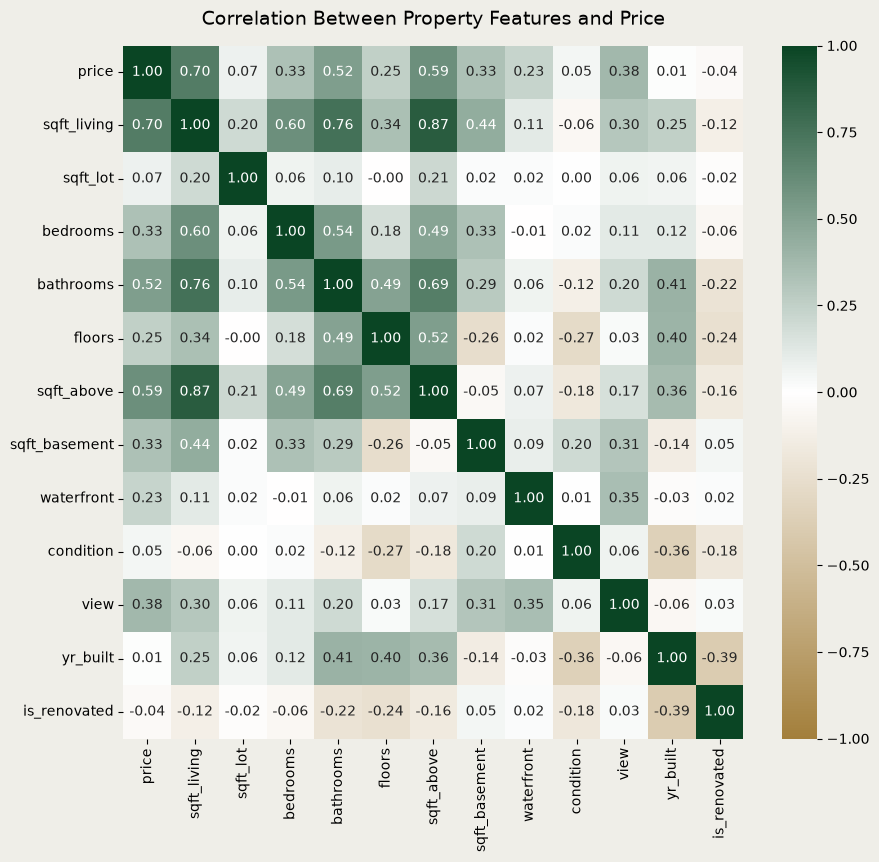

In [58]:
# Heatmap of the correlations
plt.figure(figsize=(10, 9))
sb.heatmap(corr_table, annot=True, fmt='.2f', cmap=sb.blend_palette(['#a37f3b', 'white', '#0a4524'], as_cmap=True), vmin=-1, vmax=1)
plt.title("Correlation Between Property Features and Price", fontsize=14, pad=15)
plt.show()

### Seattle vs. the rest of King County
Seattle has 34% of all sales, so I compared it with all the other cities together. The question is whether living area predicts price equally well in both groups.

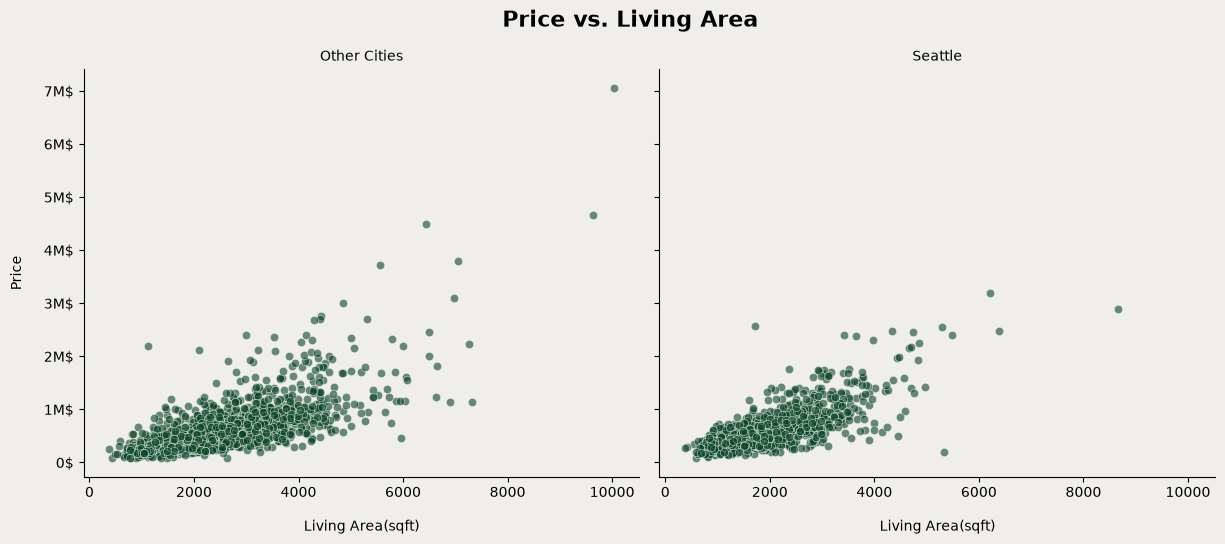

In [59]:
# Price in millions of USD -a new column, so the original price column is not changed
df["price_m"]=df["price"]/ 1000000

g=sb.relplot(data=df,x='sqft_living',y='price_m',col='city_group',kind='scatter',color='#0a4524',alpha=0.6,height=5,aspect=1.2,)
g.fig.suptitle('Price vs. Living Area',fontsize=16,y=1.05,weight='bold',)
g.set_axis_labels('Living Area(sqft)','Price',labelpad=14)
plt.yticks([0, 1, 2, 3, 4, 5, 6, 7],['0$','1M$','2M$','3M$','4M$','5M$','6M$','7M$'])
g.set_titles(col_template='{col_name}')
plt.show()

In [60]:
# Correlation between living area and price in Seattle and Other cities
df[df["city_group"] == "Seattle"][["sqft_living", "price"]].corr()

,sqft_living,price
sqft_living,1.000000,0.745565
price,0.745565,1.000000


In [61]:
df[df["city_group"] == "Other Cities"][["sqft_living", "price"]].corr()

,sqft_living,price
sqft_living,1.000000,0.725463
price,0.725463,1.000000


**What the charts show**
- **Seattle:** Prices rise with living area, with a correlation of 0.75.
- **Other cities:** The relationship is almost as strong (correlation 0.73).
- **Conclusion:** Living area is related to price to a very similar degree in Seattle and in the other cities (0.75 vs 0.73). So size does not separate Seattle from the rest; location adds to the price on top of size, which fits the earlier finding that the most expensive cities are small and wealthy.

-----------------------------------------------------------------------------------------------------------------------------------------------------
-----------------------------------------------------------------------------------------------------------------------------------------------------

##  Conclusions

### What Drives Home Prices in King County?
**Living area is the strongest single factor related to home prices in King County, and location also plays an important role.** Living area alone explains about half of the differences in price (correlation 0.70). Location also matters: the most expensive cities, such as Medina, Clyde Hill and Mercer Island, are small and wealthy. The link between size and price is similar in Seattle (0.75) and in the other cities (0.73), so the price differences between cities are not explained by size alone. Waterfront and view are linked to higher prices, but very few homes have them.

### Main findings
1. **Size is the strongest factor.** Living area has the highest correlation with price (0.70), followed by above-ground area (0.59) and bathrooms (0.52). These three overlap, because bigger homes usually have more of everything.
2. **Location matters.** Seattle has 34% of all sales but is not the most expensive city. The median price in Medina (2,100,000 USD) is about 4.3 times higher than in Seattle (490,000 USD), although Medina has only 11 sales."
3. **Waterfront and view are linked to higher prices.** Waterfront homes (only 30 homes, 0.7%) tend to sell for more than other homes, and so do homes with a good view. Because these homes are so rare, their effect on the overall correlation is small.
4. **Condition, year built and renovation show almost no relationship with price** (correlation of 0.05 or less).
5. **Lot size is not a strong predictor** (correlation 0.07). In this data, a bigger lot is only weakly related to a higher price.
6. **New homes are built differently.** The 78 homes built in 2014 stand on small lots, have more floors and bathrooms, and about 90% of them sold for less than 1 million USD.

### Notes on the Data
- Correlation does not prove cause. For example, a home may be expensive because of its location and not only because of its size.
- During cleaning I removed 55 rows (1.2%) with clearly invalid values.
- The dataset has no information on school quality, crime, or distance to the city center, which may also affect prices.

### What this means for buyers and sellers
**Buyers**
- Compare homes by price per square foot, and compare only similar homes: the same area, the same size and the same number of floors, because prices differ a lot between cities.
- Seattle has the most sales (34%) and lower prices than the wealthy cities, so buyers there have more choice and may have more room to negotiate.
- In the wealthy cities, such as Medina, Clyde Hill and Mercer Island, there are fewer sales and prices are high. Buyers there should expect less choice and less room to negotiate, and may need to wait for the right deal.
- In the weekly data, weeks with more sales also had lower prices, so busy weeks may offer better deals, but this rests on only 9 weeks.

**Sellers and agents**
- Agents can choose between quantity and quality. In Seattle there are sales all the time, so there is a lot of work, but each deal is worth less. In the wealthy small cities, such as Medina, Clyde Hill and Mercer Island, each sale is worth much more, but sales are rare, so there may be long quiet periods between deals.
- When few homes are for sale and several buyers are interested, every agent competes for every listing, so it pays to stay close to the market and to build relationships before a home is listed.
- Sellers in Seattle compete with many similar homes, so a realistic price matters. Price a home by comparing it with similar homes in the same city, because a county-wide average hides large differences between cities.
- Extra living area, bathrooms, water access and a good view can justify a higher price.

Note: the data shows prices and the number of sales, not supply, demand or negotiations, so these points are practical suggestions based on that pattern.